In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)

print("Libraries imported successfully!")



Libraries imported successfully!


In [4]:
## Loading The Dataset
df = pd.read_csv(r"C:\Users\shelo\Documents\Umzi Inventory Analysis\Data\inventory_demand_consolidated.csv")
print("Dataset loaded successfully!")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully!
Rows: 13495
Columns: 37


In [6]:
df.head()

,transaction_id,transaction_date,transaction_type,transaction_status,status_reason,order_reference,order_date,product_id,product_name,product_category,product_subcategory,warehouse_location,warehouse_province,supplier_name,supplier_location,supplier_country,supplier_lead_time_days,customer_id,customer_type,customer_location,quantity_ordered,quantity,stock_movement_qty,unfilled_quantity,stock_received,opening_stock,stock_on_hand,reorder_level,safety_stock_level,unit_cost_zar,unit_selling_price_zar,total_cost_zar,total_revenue_zar,gross_profit_zar,expected_delivery_date,actual_delivery_date,delivery_status
0,TXN000001,2024-01-01,Sale,Completed,NaN,SO000013,NaN,PRD008,Soundbar 2.1,Electronics,Audio,Pretoria,Gauteng,NaN,NaN,NaN,NaN,CUS039,Hospitality,Richards Bay,5.0,3.0,-3,2.0,NaN,3,0,1,1,51.09,64.58,153.27,193.74,40.47,NaN,NaN,NaN
1,TXN000002,2024-01-01,Sale,Completed,NaN,SO000019,NaN,PRD012,AAA Batteries 8-Pack,Electronics,Batteries & Lighting,Pretoria,Gauteng,NaN,NaN,NaN,NaN,CUS110,Wholesaler,East London,12.0,12.0,-12,0.0,NaN,14,2,23,4,170.20,210.78,2042.40,2529.36,486.96,NaN,NaN,NaN
2,TXN000003,2024-01-01,Sale,Completed,NaN,SO000039,NaN,PRD022,Microfibre Pillowcase Pair,Household goods,Bedding & Linen,Pretoria,Gauteng,NaN,NaN,NaN,NaN,CUS117,Supermarket Chain,Kimberley,6.0,6.0,-6,0.0,NaN,18,12,27,5,46.28,58.57,277.68,351.42,73.74,NaN,NaN,NaN
3,TXN000004,2024-01-01,Sale,Completed,NaN,SO000062,NaN,PRD047,Face Cleanser 150ml,Personal care,Skin Care,Cape Town,Western Cape,NaN,NaN,NaN,NaN,CUS245,Corporate Office,Gqeberha,13.0,13.0,-13,0.0,NaN,67,54,31,16,27.52,40.11,357.76,521.43,163.67,NaN,NaN,NaN
4,TXN000005,2024-01-01,Sale,Completed,NaN,SO000063,NaN,PRD050,Hand Cream 100ml,Personal care,Skin Care,Johannesburg,Gauteng,NaN,NaN,NaN,NaN,CUS124,Independent Retailer,Cape Town,10.0,10.0,-10,0.0,NaN,38,28,53,9,129.61,195.20,1296.10,1952.00,655.90,NaN,NaN,NaN


In [7]:
df.tail()

,transaction_id,transaction_date,transaction_type,transaction_status,status_reason,order_reference,order_date,product_id,product_name,product_category,product_subcategory,warehouse_location,warehouse_province,supplier_name,supplier_location,supplier_country,supplier_lead_time_days,customer_id,customer_type,customer_location,quantity_ordered,quantity,stock_movement_qty,unfilled_quantity,stock_received,opening_stock,stock_on_hand,reorder_level,safety_stock_level,unit_cost_zar,unit_selling_price_zar,total_cost_zar,total_revenue_zar,gross_profit_zar,expected_delivery_date,actual_delivery_date,delivery_status
13490,TXN013491,2025-12-31,Sale,Completed,NaN,SO013491,NaN,PRD059,Sanitary Pads 10s,Personal care,Oral & Hygiene,Durban,KwaZulu-Natal,NaN,NaN,NaN,NaN,CUS113,Wholesaler,Johannesburg,14.0,14.0,-14,0.0,NaN,72,58,102,17,133.53,187.30,1869.42,2622.20,752.78,NaN,NaN,NaN
13491,TXN013492,2025-12-31,Sale,Completed,NaN,SO013492,NaN,PRD060,Antibacterial Soap 500ml,Personal care,Oral & Hygiene,Cape Town,Western Cape,NaN,NaN,NaN,NaN,CUS246,Supermarket Chain,Kimberley,22.0,22.0,-22,0.0,NaN,82,60,10,5,132.62,185.02,2917.64,4070.44,1152.80,NaN,NaN,NaN
13492,TXN013493,2025-12-31,Sale,Completed,NaN,SO013493,NaN,PRD080,Disinfectant Spray 500ml,Cleaning products,Surface Cleaners,Cape Town,Western Cape,NaN,NaN,NaN,NaN,CUS202,Hospitality,Richards Bay,10.0,10.0,-10,0.0,NaN,34,24,60,10,87.77,106.24,877.70,1062.40,184.70,NaN,NaN,NaN
13493,TXN013494,2025-12-31,Sale,Completed,NaN,SO013494,NaN,PRD090,Plastic Bucket 10L,Cleaning products,Cleaning Tools,Durban,KwaZulu-Natal,NaN,NaN,NaN,NaN,CUS112,Wholesaler,Johannesburg,20.0,20.0,-20,0.0,NaN,33,13,26,4,22.61,30.15,452.20,603.00,150.80,NaN,NaN,NaN
13494,TXN013495,2025-12-31,Purchase,Pending,Open - not yet delivered,PO013495,2025-12-31,PRD090,Plastic Bucket 10L,Cleaning products,Cleaning Tools,Durban,KwaZulu-Natal,Hanoi Plastics JSC,Hanoi,Vietnam,38.0,NaN,NaN,NaN,63.0,NaN,0,NaN,NaN,13,13,26,4,22.61,NaN,NaN,NaN,NaN,2026-02-07,NaN,In Transit


In [8]:
df.sample(10)

,transaction_id,transaction_date,transaction_type,transaction_status,status_reason,order_reference,order_date,product_id,product_name,product_category,product_subcategory,warehouse_location,warehouse_province,supplier_name,supplier_location,supplier_country,supplier_lead_time_days,customer_id,customer_type,customer_location,quantity_ordered,quantity,stock_movement_qty,unfilled_quantity,stock_received,opening_stock,stock_on_hand,reorder_level,safety_stock_level,unit_cost_zar,unit_selling_price_zar,total_cost_zar,total_revenue_zar,gross_profit_zar,expected_delivery_date,actual_delivery_date,delivery_status
9764,TXN009765,2025-06-15,Sale,Completed,NaN,SO009817,NaN,PRD104,Double Wall Socket,Hardware,Plumbing & Electrical,Johannesburg,Gauteng,NaN,NaN,NaN,NaN,CUS017,Supermarket Chain,Ekurhuleni,9.0,9.0,-9,0.0,NaN,24,15,43,7,18.45,24.02,166.05,216.18,50.13,NaN,NaN,NaN
13181,TXN013182,2025-12-19,Sale,Completed,NaN,SO013203,NaN,PRD056,Toothpaste 100ml,Personal care,Oral & Hygiene,Pretoria,Gauteng,NaN,NaN,NaN,NaN,CUS131,Independent Retailer,Kimberley,16.0,16.0,-16,0.0,NaN,61,45,44,8,138.96,198.62,2223.36,3177.92,954.56,NaN,NaN,NaN
6833,TXN006834,2025-01-12,Sale,Completed,NaN,SO006884,NaN,PRD047,Face Cleanser 150ml,Personal care,Skin Care,Cape Town,Western Cape,NaN,NaN,NaN,NaN,CUS040,Wholesaler,Pietermaritzburg,8.0,8.0,-8,0.0,NaN,67,59,31,16,27.52,40.11,220.16,320.88,100.72,NaN,NaN,NaN
1607,TXN001608,2024-03-28,Sale,Completed,NaN,SO001654,NaN,PRD032,Instant Coffee 200g,Food and beverages,Pantry,Durban,KwaZulu-Natal,NaN,NaN,NaN,NaN,CUS147,Supermarket Chain,Richards Bay,13.0,13.0,-13,0.0,NaN,13,0,1,1,89.53,102.48,1163.89,1332.24,168.35,NaN,NaN,NaN
4556,TXN004557,2024-09-17,Sale,Completed,NaN,SO004610,NaN,PRD025,Fleece Throw Blanket,Household goods,Bedding & Linen,Durban,KwaZulu-Natal,NaN,NaN,NaN,NaN,CUS148,Corporate Office,Bloemfontein,9.0,9.0,-9,0.0,NaN,23,14,25,4,141.29,199.75,1271.61,1797.75,526.14,NaN,NaN,NaN
10443,TXN010444,2025-07-25,Sale,Cancelled,Out of stock,SO010490,NaN,PRD032,Instant Coffee 200g,Food and beverages,Pantry,Durban,KwaZulu-Natal,NaN,NaN,NaN,NaN,CUS068,Independent Retailer,Durban,10.0,0.0,0,10.0,NaN,0,0,1,1,89.53,102.48,NaN,NaN,NaN,NaN,NaN,NaN
7557,TXN007558,2025-02-17,Sale,Completed,NaN,SO007615,NaN,PRD069,Highlighters 4-Pack,Office supplies,Writing,Johannesburg,Gauteng,NaN,NaN,NaN,NaN,CUS068,Independent Retailer,Durban,25.0,25.0,-25,0.0,NaN,205,180,57,11,54.53,75.16,1363.25,1879.00,515.75,NaN,NaN,NaN
149,TXN000150,2024-01-10,Sale,Completed,NaN,SO000303,NaN,PRD059,Sanitary Pads 10s,Personal care,Oral & Hygiene,Durban,KwaZulu-Natal,NaN,NaN,NaN,NaN,CUS086,Independent Retailer,Pietermaritzburg,12.0,12.0,-12,0.0,NaN,73,61,102,17,133.53,187.30,1602.36,2247.60,645.24,NaN,NaN,NaN
298,TXN000299,2024-01-19,Sale,Cancelled,Out of stock,SO000454,NaN,PRD067,Gel Pens Assorted 10,Office supplies,Writing,Johannesburg,Gauteng,NaN,NaN,NaN,NaN,CUS011,Corporate Office,Mbombela,18.0,0.0,0,18.0,NaN,0,0,54,11,99.50,126.23,NaN,NaN,NaN,NaN,NaN,NaN
6324,TXN006325,2024-12-19,Purchase,Completed,Partial delivery,PO005505,2024-11-03,PRD018,Glass Food Container Set,Household goods,Kitchenware,Durban,KwaZulu-Natal,Hanoi Plastics JSC,Hanoi,Vietnam,38.0,NaN,NaN,NaN,30.0,28.0,28,NaN,28.0,0,28,13,2,242.93,NaN,6802.04,NaN,NaN,2024-12-11,2024-12-19,Late


In [9]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 13495 entries, 0 to 13494
Data columns (total 37 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   transaction_id           13495 non-null  str    
 1   transaction_date         13495 non-null  str    
 2   transaction_type         13495 non-null  str    
 3   transaction_status       13495 non-null  str    
 4   status_reason            1988 non-null   str    
 5   order_reference          13495 non-null  str    
 6   order_date               1658 non-null   str    
 7   product_id               13495 non-null  str    
 8   product_name             13495 non-null  str    
 9   product_category         13495 non-null  str    
 10  product_subcategory      13495 non-null  str    
 11  warehouse_location       13495 non-null  str    
 12  warehouse_province       13495 non-null  str    
 13  supplier_name            1658 non-null   str    
 14  supplier_location        1658 non

In [10]:
df.describe(include="all").T

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
transaction_id,13495,13495,TXN000001,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_date,13495,770,2025-11-26,38,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_type,13495,4,Sale,11352,NaN,NaN,NaN,NaN,NaN,NaN,NaN
transaction_status,13495,3,Completed,12197,NaN,NaN,NaN,NaN,NaN,NaN,NaN
status_reason,1988,7,Out of stock,907,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_reference,13495,13191,SO000163,2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
order_date,1658,647,2024-01-01,143,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_id,13495,105,PRD051,448,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_name,13495,308,Shampoo 400ml,437,NaN,NaN,NaN,NaN,NaN,NaN,NaN
product_category,13495,14,Personal care,2875,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [11]:
missing_values = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2)
})

missing_values = missing_values[missing_values["Missing Count"] > 0]

missing_values.sort_values("Missing Percentage", ascending=False)

,Missing Count,Missing Percentage
actual_delivery_date,11895,88.14
stock_received,11895,88.14
delivery_status,11837,87.71
order_date,11837,87.71
supplier_name,11837,87.71
supplier_location,11837,87.71
supplier_country,11837,87.71
supplier_lead_time_days,11837,87.71
expected_delivery_date,11837,87.71
status_reason,11507,85.27


In [12]:
print("Transaction types:")
print(df["transaction_type"].value_counts())

print("\nTransaction statuses:")
print(df["transaction_status"].value_counts())

print("\nDuplicate transaction IDs:")
print(df["transaction_id"].duplicated().sum())

Transaction types:
transaction_type
Sale                11352
Purchase             1658
Return                304
Stock Adjustment      181
Name: count, dtype: int64

Transaction statuses:
transaction_status
Completed    12197
Cancelled     1240
Pending         58
Name: count, dtype: int64

Duplicate transaction IDs:
0


In [13]:
## 3 Data Cleaning 

In [14]:
df_clean = df.copy()

print("Working copy created.")


Working copy created.


In [15]:
dates = df_clean["transaction_date"].astype("string").str.strip()

slash_dates = dates.str.contains("/", na=False)

df_clean["transaction_date"] = pd.NaT

df_clean.loc[slash_dates, "transaction_date"] = pd.to_datetime(
    dates[slash_dates],
    format="%d/%m/%Y"
)

df_clean.loc[~slash_dates, "transaction_date"] = pd.to_datetime(
    dates[~slash_dates],
    format="%Y-%m-%d"
)

In [16]:
print("Transaction date data type:", df_clean["transaction_date"].dtype)
print("Missing dates:", df_clean["transaction_date"].isna().sum())
print("Earliest transaction:", df_clean["transaction_date"].min())
print("Latest transaction:", df_clean["transaction_date"].max())

Transaction date data type: datetime64[ns]
Missing dates: 0
Earliest transaction: 2024-01-01 00:00:00
Latest transaction: 2025-12-31 00:00:00


In [17]:
date_columns = [
    "order_date",
    "expected_delivery_date",
    "actual_delivery_date"
]

for col in date_columns:
    df_clean[col] = pd.to_datetime(df_clean[col], errors="coerce")

print(df_clean[date_columns].dtypes)

order_date                datetime64[us]
expected_delivery_date    datetime64[us]
actual_delivery_date      datetime64[us]
dtype: object


In [18]:
df_clean["product_name"] = (
    df_clean["product_name"]
    .str.strip()
    .str.replace(r"\s+", " ", regex=True)
)

df_clean["product_category"] = (
    df_clean["product_category"]
    .str.strip()
    .str.capitalize()
)

In [19]:
print("Unique product categories:")
print(sorted(df_clean["product_category"].dropna().unique()))

print("\nUnique product names:", df_clean["product_name"].nunique())

Unique product categories:
['Cleaning products', 'Electronics', 'Food and beverages', 'Hardware', 'Household goods', 'Office supplies', 'Personal care']

Unique product names: 105


In [20]:
print("Unique supplier names:")
print(sorted(df_clean["supplier_name"].dropna().unique()))

Unique supplier names:
['Bayside Electronics Distribution (Pty) Limited', 'Bayside Electronics Distribution (Pty) Ltd', 'Bayside Electronics Distribution Pty Ltd', 'Cape Fresh Foods Co (Pty) Limited', 'Cape Fresh Foods Co (Pty) Ltd', 'Cape Fresh Foods Co Pty Ltd', 'Eastern Cape Beverages (Pty) Limited', 'Eastern Cape Beverages (Pty) Ltd', 'Eastern Cape Beverages Pty Ltd', 'Gauteng Hardware Co (Pty) Limited', 'Gauteng Hardware Co (Pty) Ltd', 'Hanoi Plastics JSC', 'Milan Stationery Group SpA', 'Mumbai Household Imports Pvt Limited', 'Mumbai Household Imports Pvt Ltd', 'Ocean Blue Personal Care (Pty) Limited', 'Ocean Blue Personal Care (Pty) Ltd', 'Ocean Blue Personal Care Pty Ltd', 'Pinetown Cleaning Chemicals (Pty) Limited', 'Pinetown Cleaning Chemicals (Pty) Ltd', 'Pinetown Cleaning Chemicals Pty Ltd', 'Rhine Office Systems GmbH', 'Shenzhen Star Electronics Limited', 'Shenzhen Star Electronics Ltd', 'cape fresh foods co (pty) ltd', 'eastern cape beverages (pty) ltd', 'hanoi plastics js

In [21]:
customer_transactions = df_clean[
    df_clean["transaction_type"].isin(["Sale", "Return"])
]

print(
    "Missing customer locations:",
    customer_transactions["customer_location"].isna().sum()
)

Missing customer locations: 90


In [22]:
df_clean["supplier_name"] = (
    df_clean["supplier_name"]
    .str.lower()
    .str.replace(r"[()]", "", regex=True)
    .str.replace(r"\s+limited$", " ltd", regex=True)
    .str.replace(r"\s+", " ", regex=True)
    .str.strip()
    .str.title()
)

# Restore international supplier abbreviations
df_clean["supplier_name"] = df_clean["supplier_name"].replace({
    "Hanoi Plastics Jsc": "Hanoi Plastics JSC",
    "Milan Stationery Group Spa": "Milan Stationery Group SpA",
    "Rhine Office Systems Gmbh": "Rhine Office Systems GmbH"
})

In [23]:
print("Unique suppliers:", df_clean["supplier_name"].nunique())

print("\nStandardised supplier names:")
print(sorted(df_clean["supplier_name"].dropna().unique()))

Unique suppliers: 11

Standardised supplier names:
['Bayside Electronics Distribution Pty Ltd', 'Cape Fresh Foods Co Pty Ltd', 'Eastern Cape Beverages Pty Ltd', 'Gauteng Hardware Co Pty Ltd', 'Hanoi Plastics JSC', 'Milan Stationery Group SpA', 'Mumbai Household Imports Pvt Ltd', 'Ocean Blue Personal Care Pty Ltd', 'Pinetown Cleaning Chemicals Pty Ltd', 'Rhine Office Systems GmbH', 'Shenzhen Star Electronics Ltd']


In [24]:
## Data Check

In [25]:
print("Dataset dimensions:", df_clean.shape)

print("\nDuplicate transaction IDs:",
      df_clean["transaction_id"].duplicated().sum())

print("\nMissing transaction dates:",
      df_clean["transaction_date"].isna().sum())

print("\nUnique products:",
      df_clean["product_name"].nunique())

print("\nUnique categories:",
      df_clean["product_category"].nunique())

print("\nUnique suppliers:",
      df_clean["supplier_name"].nunique())
      

Dataset dimensions: (13495, 37)

Duplicate transaction IDs: 0

Missing transaction dates: 0

Unique products: 105

Unique categories: 7

Unique suppliers: 11


In [26]:
sales = df_clean[
    (df_clean["transaction_type"] == "Sale") &
    (df_clean["transaction_status"] == "Completed")
]

In [27]:
total_revenue = sales["total_revenue_zar"].sum()

print("Total sales revenue: R", round(total_revenue, 2))

Total sales revenue: R 14551475.2


In [28]:
top_products = (
    sales.groupby("product_name")["quantity"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

print(top_products)

product_name
Still Water 5L              6410.0
Detangling Hair Brush       5892.0
Shampoo 400ml               4045.0
Sanitary Pads 10s           4008.0
Milk Chocolate Bar 80g      3852.0
Face Cleanser 150ml         3482.0
Exercise Book 80 Pages      3322.0
Biltong Snack Pack 50g      3278.0
Wall Anchors 6mm 50-Pack    3185.0
Sunflower Oil 2L            3137.0
Name: quantity, dtype: float64


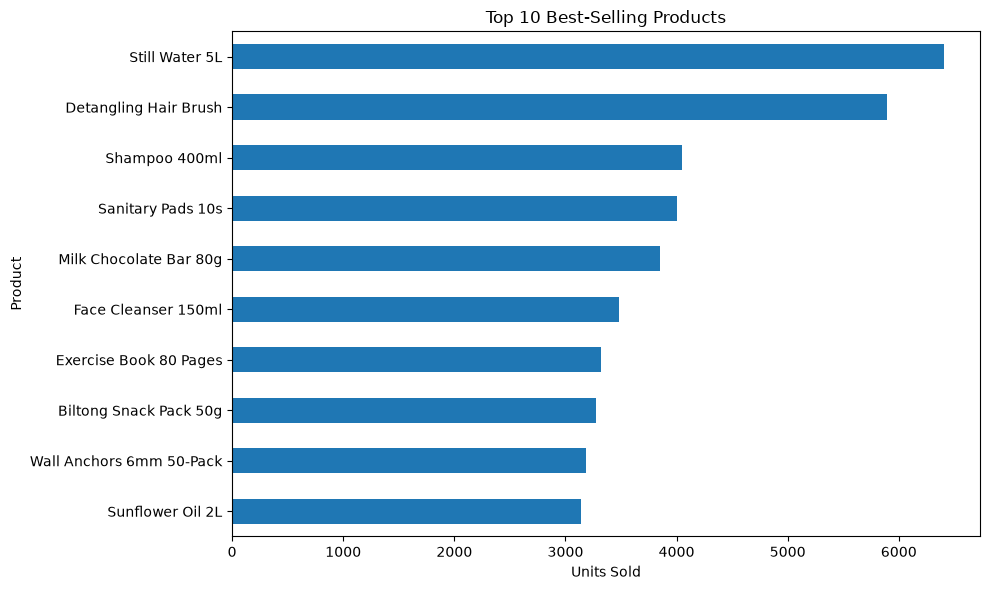

In [29]:
top_products.sort_values().plot(kind="barh", figsize=(10, 6))

plt.title("Top 10 Best-Selling Products")
plt.xlabel("Units Sold")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [30]:
stockouts = sales.groupby("product_name")["unfilled_quantity"].sum()

stockouts = stockouts.sort_values(ascending=False)

print(stockouts.head(10))

product_name
Energy Drink 500ml          282.0
Disinfectant Spray 500ml    237.0
Basmati Rice 5kg            210.0
A4 Copy Paper 500 Sheets    207.0
Bleach 2L                   175.0
HB Pencils Box of 12        170.0
Salted Popcorn 100g         160.0
Mixed Nuts 250g             144.0
Cake Flour 2.5kg            126.0
Plastic Laundry Basket      125.0
Name: unfilled_quantity, dtype: float64


In [31]:
total_unfilled = sales["unfilled_quantity"].sum()

print("Total unfulfilled units:", total_unfilled)

Total unfulfilled units: 6935.0


In [32]:
sales["lost_revenue_estimate"] = (
    sales["unfilled_quantity"] * sales["unit_selling_price_zar"]
)

lost_revenue = sales.groupby("product_name")["lost_revenue_estimate"].sum()

print(lost_revenue.sort_values(ascending=False).head(10).round(2))

product_name
Glass Food Container Set     34775.89
Plastic Laundry Basket       34037.50
Aux Cable 3.5mm              31906.32
Disinfectant Spray 500ml     24945.24
Bleach 2L                    22204.75
Wall Anchors 6mm 50-Pack     19410.28
Tempered Screen Protector    19288.29
HB Pencils Box of 12         18548.70
Energy Drink 500ml           18302.61
Hand Cream 100ml             18153.60
Name: lost_revenue_estimate, dtype: float64


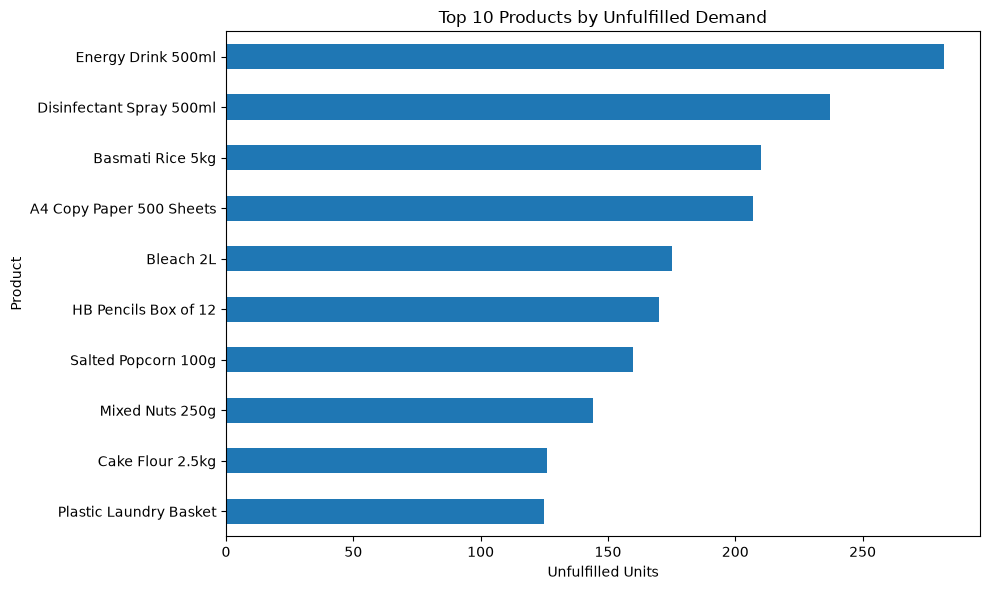

In [33]:
stockouts.head(10).sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Top 10 Products by Unfulfilled Demand")
plt.xlabel("Unfulfilled Units")
plt.ylabel("Product")
plt.tight_layout()
plt.show()

In [34]:
purchases = df_clean[
    (df_clean["transaction_type"] == "Purchase") &
    (df_clean["transaction_status"] == "Completed")
].copy()

purchases = purchases.dropna(
    subset=["actual_delivery_date", "expected_delivery_date"]
)

print("Completed deliveries:", len(purchases))

Completed deliveries: 1600


In [35]:
purchases["delay_days"] = (
    purchases["actual_delivery_date"] -
    purchases["expected_delivery_date"]
).dt.days

purchases["late_delivery"] = purchases["delay_days"] > 0

print("Late deliveries:", purchases["late_delivery"].sum())

Late deliveries: 790


In [36]:
supplier_performance = purchases.groupby("supplier_name").agg(
    total_deliveries=("transaction_id", "count"),
    average_delay=("delay_days", "mean"),
    late_deliveries=("late_delivery", "sum")
)

supplier_performance["late_delivery_rate"] = (
    supplier_performance["late_deliveries"] /
    supplier_performance["total_deliveries"] * 100
)

print(
    supplier_performance
    .sort_values("late_delivery_rate", ascending=False)
    .round(2)
)


                                          total_deliveries  average_delay  \
supplier_name                                                               
Hanoi Plastics JSC                                     334           6.04   
Gauteng Hardware Co Pty Ltd                             78           3.69   
Mumbai Household Imports Pvt Ltd                       219           2.53   
Shenzhen Star Electronics Ltd                          142           2.07   
Ocean Blue Personal Care Pty Ltd                       151           0.60   
Milan Stationery Group SpA                             125           0.90   
Pinetown Cleaning Chemicals Pty Ltd                    141           0.40   
Cape Fresh Foods Co Pty Ltd                            165           0.25   
Rhine Office Systems GmbH                              102           0.14   
Eastern Cape Beverages Pty Ltd                          83           0.12   
Bayside Electronics Distribution Pty Ltd                60           0.25   

In [37]:
purchases["partial_delivery"] = (
    purchases["stock_received"] < purchases["quantity_ordered"]
)

partial_deliveries = purchases.groupby("supplier_name")[
    "partial_delivery"
].sum()

print(partial_deliveries.sort_values(ascending=False))

supplier_name
Hanoi Plastics JSC                          99
Gauteng Hardware Co Pty Ltd                 18
Shenzhen Star Electronics Ltd               17
Ocean Blue Personal Care Pty Ltd            15
Mumbai Household Imports Pvt Ltd            14
Milan Stationery Group SpA                  11
Pinetown Cleaning Chemicals Pty Ltd         11
Rhine Office Systems GmbH                    9
Cape Fresh Foods Co Pty Ltd                  8
Eastern Cape Beverages Pty Ltd               2
Bayside Electronics Distribution Pty Ltd     1
Name: partial_delivery, dtype: int64


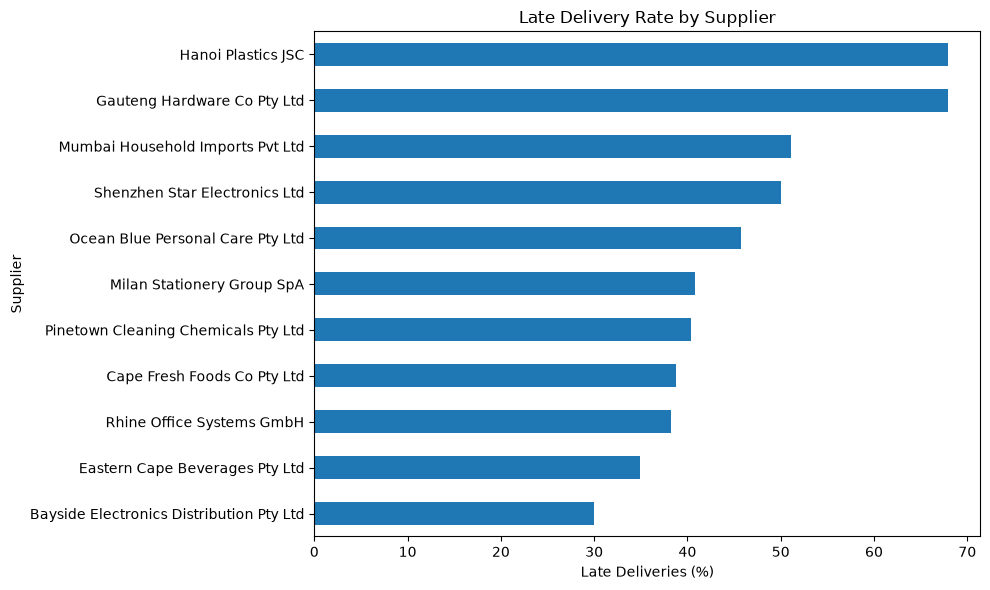

In [38]:
supplier_performance["late_delivery_rate"].sort_values().plot(
    kind="barh",
    figsize=(10, 6)
)

plt.title("Late Delivery Rate by Supplier")
plt.xlabel("Late Deliveries (%)")
plt.ylabel("Supplier")
plt.tight_layout()
plt.show()

In [39]:
df_clean.to_csv("inventory_demand_cleaned.csv", index=False)

In [40]:
print(df_clean["supplier_name"].nunique())

print(sorted(df_clean["supplier_name"].dropna().unique()))

11
['Bayside Electronics Distribution Pty Ltd', 'Cape Fresh Foods Co Pty Ltd', 'Eastern Cape Beverages Pty Ltd', 'Gauteng Hardware Co Pty Ltd', 'Hanoi Plastics JSC', 'Milan Stationery Group SpA', 'Mumbai Household Imports Pvt Ltd', 'Ocean Blue Personal Care Pty Ltd', 'Pinetown Cleaning Chemicals Pty Ltd', 'Rhine Office Systems GmbH', 'Shenzhen Star Electronics Ltd']


In [41]:
df_clean.to_csv("inventory_demand_cleaned2.csv", index=False)

In [42]:
total_units_sold = sales["quantity"].sum()

total_lost_revenue = sales["unfilled_quantity"].mul(
    sales["unit_selling_price_zar"]
).sum()

print("Total units sold:", total_units_sold)
print("Total estimated lost revenue: R", round(total_lost_revenue, 2))

Total units sold: 138181.0
Total estimated lost revenue: R 790389.53
